### Import Library & Load Data Hasil Preprocessing

In [12]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat data bersih dari hasil preprocessing
data_prep = joblib.load('../dataset/data_hasil_preprocessing.pkl')
df_bersih = data_prep['df_bersih']

kolom_numerik = [
    'price', 
    'bed_rooms', 
    'bath_rooms', 
    'carport', 
    'land_area', 
    'building_area'
]

print(f"Data berhasil dimuat! Ukuran data bersih: {df_bersih.shape[0]} baris, {df_bersih.shape[1]} kolom")
display(df_bersih[kolom_numerik].head())

Data berhasil dimuat! Ukuran data bersih: 7573 baris, 8 kolom


,price,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,2,4,2,250.0,350.0
1,2700000000,4,2,0,100.0,225.0
2,2200000000,3,3,0,60.0,140.0
3,1900000000,3,2,0,60.0,120.0
4,2100000000,4,3,0,56.0,108.0


### Visualisasi Distribusi Data Numerik Setelah Preprocessing

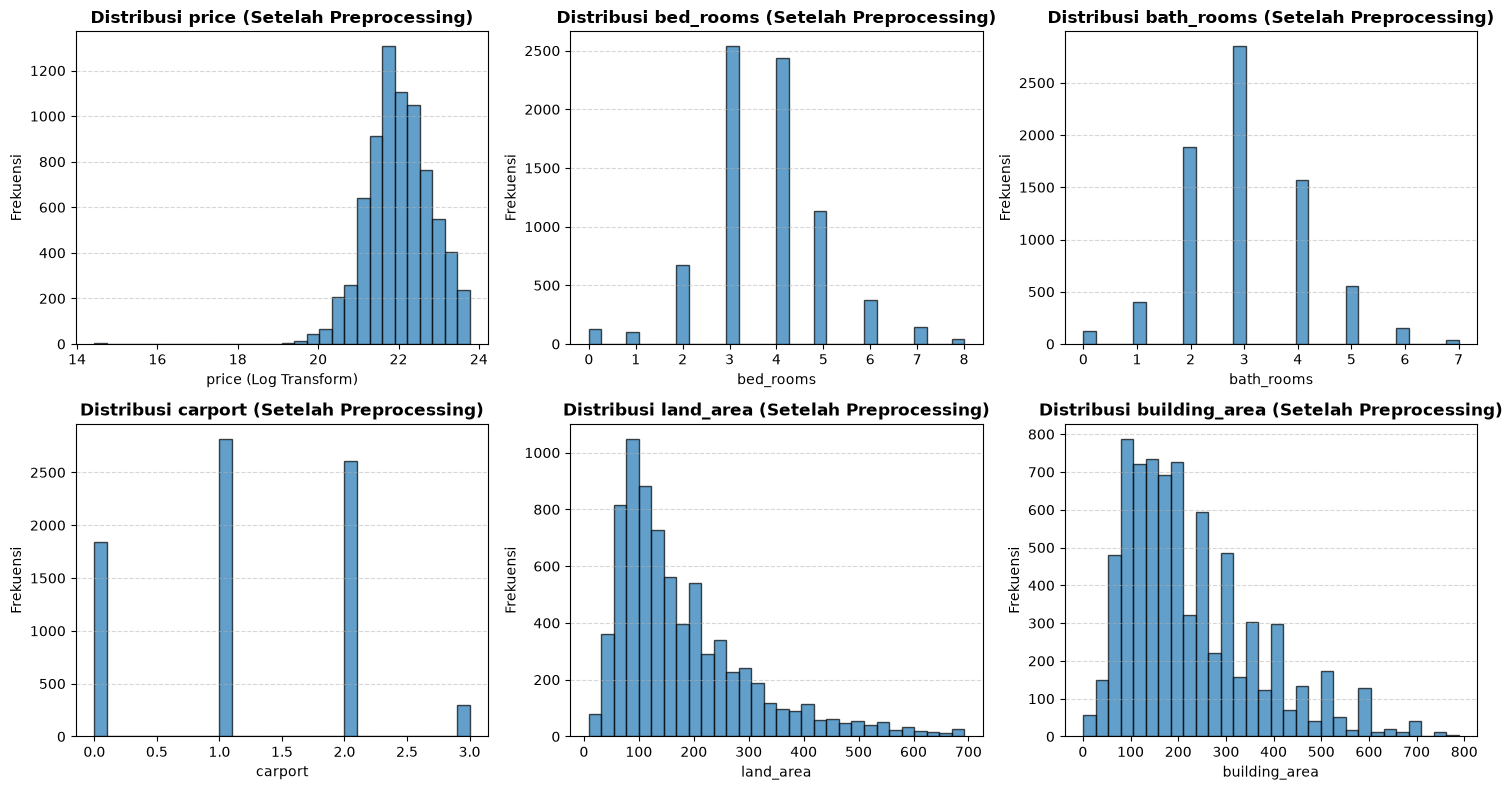

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_numerik):
    # Khusus kolom price ditampilkan dalam skala logaritmik sesuai tahapan preprocessing
    data_plot = np.log1p(df_bersih[col]) if col == 'price' else df_bersih[col]
    label_x = f'{col} (Log Transform)' if col == 'price' else col
    
    axes[i].hist(data_plot, bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribusi {col} (Setelah Preprocessing)', fontweight='bold')
    axes[i].set_xlabel(label_x)
    axes[i].set_ylabel('Frekuensi')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Visualisasi Boxplot Setelah Penghapusan Outlier

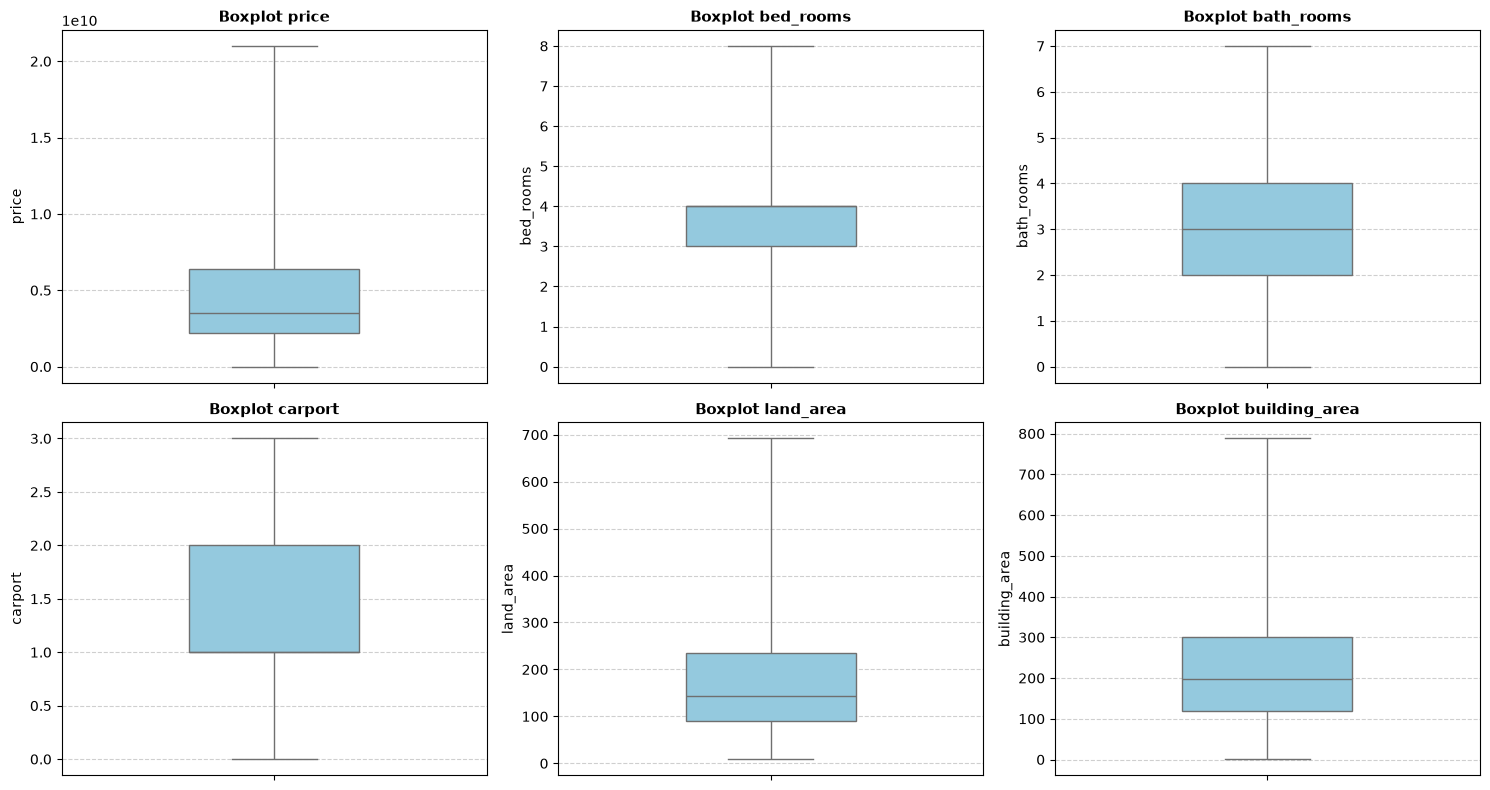

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_numerik):
    sns.boxplot(y=df_bersih[col], ax=axes[i], color='skyblue', width=0.4, whis=(0, 100))
    axes[i].set_title(f'Boxplot {col}', fontweight='bold', fontsize=11)
    axes[i].set_ylabel(col)
    axes[i].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()